#### Load the Env Variables

In [ ]:
from dotenv import load_dotenv
load_dotenv()

In [94]:
import os
apiKey = os.getenv("GROQ_API_KEY")

In [ ]:
apiKey

#### Simple QnA Bot without LangChain - With Groq

In [95]:
from groq import Groq

client = Groq()
completion = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
      {
        "role": "user",
        "content": "Explain me the Gen-ai"
      }
    ],
    max_completion_tokens=100
)

In [96]:
print(completion.choices[0].message.content)

## What is Generative AI?

**Generative AI (Gen‑AI)** is a branch


#### Simple QnA Bot with LangChain - With Groq

In [97]:
from langchain_groq import ChatGroq

In [98]:
llm = ChatGroq(model="openai/gpt-oss-120b")
ans = llm.invoke("Hello, Hows You ?")

In [99]:
ans.content

"Hello! I'm doing great, thank you for asking. How are you doing today?"

##### Chat with OpenAI

In [ ]:
from langchain_openai import ChatOpenAI

In [ ]:
openaiLlm = ChatOpenAI(model="gpt-5.1", api_key=os.getenv("OPENAI_API_KEY"))

In [ ]:
res = openaiLlm.invoke("Who is pm of india ?")

In [ ]:
res.content

#### Common LLM Calls with - `init_chat_model`

In [ ]:
from langchain.chat_models import init_chat_model

In [100]:

llm = init_chat_model(model=os.getenv("MODEL", "openai/gpt-oss-20b"), 
                      model_provider=os.getenv("PROVIDER", "groq"))


In [101]:
res = llm.invoke("How to write a second max finder code")
# res

In [102]:
print(res)

content='Below is a quick‑start guide to writing a *second‑maximum* (or “second‑largest”) finder.  \nIt covers the core idea, edge‑case handling, and gives you ready‑to‑copy snippets in **Python, Java, and C++**.  \nFeel free to drop the code into your favourite IDE and tweak it to your own data types or input method.\n\n---\n\n## 1. The idea in a nutshell\n\n1. **Walk the list once** (O(n) time).  \n2. Keep two variables:\n   * `max_val` – the largest value seen so far.\n   * `second_max` – the largest value *strictly smaller* than `max_val`.\n3. For every element `x`:\n   * If `x > max_val` → `second_max = max_val`, `max_val = x`.\n   * Else if `x < max_val` and (`second_max` is unset or `x > second_max`) → `second_max = x`.\n4. After the loop, `second_max` is the second largest distinct value.\n\n> **Why “strictly smaller”?**  \n> If the array contains duplicates of the maximum (e.g., `[9,9,7]`), the second‑max must be the next distinct value (`7`).  \n> If you want the *second* ele

#### Core Components of `LangChain`
##### 1. `Messages`

#### Promte - LLM -> Three types / role of prompt ['user', 'ai', 'system' ]

In [103]:

llm = init_chat_model(model=os.getenv("MODEL", "openai/gpt-oss-20b"), 
                      model_provider=os.getenv("PROVIDER", "groq"))

res = llm.invoke([ 
                  { "role":"system", "content":"You are a 7 years of python developer, but you have no idea about java programming language, if user ask for java, then just reply that 'I don't know java.'" }, 
                  { "role":"user", "content":"How to find second largest number in array using Java" } 
                  ])


In [104]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage
prompts = [
    SystemMessage(content="You are a 7 years of python developer, but you have no idea about java programming language, if user ask for java, then just reply that 'I don't know java.'"),
    HumanMessage(content="How to find second largest number in array using Java")
]

res = llm.invoke(prompts)

##### 2. `Prompt Templates`

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    {"role":"system", "content":"You are a 7 years of {language} developer"}, 
    {"role":"user", "content":"{query}"}, 
])
prompt.invoke({})

#### 3. LCEL - `|` Operator

In [105]:
question = "How to map the array"
language = "javascript"

finalprompt = prompt.invoke({"language":language, "query":question})

res = llm.invoke(finalprompt)
print(res.content)

## Quick‑start: `Array.prototype.map`

```js
const numbers = [1, 2, 3, 4];

const squares = numbers.map(n => n * n);   // [1, 4, 9, 16]
```

`map` is a pure, **immutable** array method.  
It **always** returns a new array whose length is the same as the source, and
each element is the result of applying the callback to the corresponding
element of the original array.

---

### 1️⃣ Callback signature

```js
array.map((currentValue, index, array) => {
  // return the new value for this position
});
```

| Argument | What it is | Typical use |
|----------|------------|-------------|
| `currentValue` | The element being processed | The main value you’ll transform |
| `index` | Zero‑based index | When you need the position (e.g., `index + 1`) |
| `array` | The original array | Rarely needed, but handy for context |

> **Tip:** If you only need the value, just write `map(v => …)`.

---

### 2️⃣ Common patterns

| Goal | Example |
|------|---------|
| **Simple transformation** | `const double

##### `LangChain` Chain

In [106]:
from langchain.messages import AIMessage

def getContent(llmResponse:AIMessage):
    return llmResponse.content


def shortTheMessage(msg:str):
    return msg[:100]

In [107]:
qna_chain = prompt | llm | getContent | shortTheMessage

In [108]:
res = qna_chain.invoke({"language":"english", "query":"what is gen-ai"})

In [109]:
print(len(res)) 
print(res)

100
**Gen‑AI (Generative AI)**  
Generative AI is a type of artificial‑intelligence that can *create* th


##### 4. `Memory` - Conver. History

In [110]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b")

In [111]:
res = llm.invoke("Who is Pm of india ?")

In [112]:
res.content

'The Prime Minister of India is **Narendra Modi**.'

In [113]:
res = llm.invoke("What is his age ?")

In [114]:
res.content

'I’m not sure who you’re referring to. Could you let me know which person you’re asking about?'

#### Implement history...

In [115]:
history = []

In [116]:
while True:
    query = input("User: ")
    if query == "exit":
        break
    
    history.append(HumanMessage(query))
    res = llm.invoke(history)
    history.append(AIMessage(content=res.content))
    print("AI: ", res.content)

AI:  As of 2026, the President of India is **Draupadi Murmu**. She became the 15th President of India on **25 July 2022**, succeeding Ram Nath Khurana. Draupadi Murmu is the first person from India's tribal community and the first woman from a tribal background to hold the office.
AI:  Draupadi Murmu was born on **30 June 1958**.  
Today, **12 October 2026**, she is **68 years old**—specifically 68 years, 3 months, and 12 days.


In [117]:
history

[HumanMessage(content='Who is the president of india ?', additional_kwargs={}, response_metadata={}),
 AIMessage(content="As of 2026, the President of India is **Draupadi Murmu**. She became the 15th President of India on **25\u202fJuly\u202f2022**, succeeding Ram\u202fNath\u202fKhurana. Draupadi\u202fMurmu is the first person from India's tribal community and the first woman from a tribal background to hold the office.", additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='How old is she ?', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Draupadi\u202fMurmu was born on **30\u202fJune\u202f1958**.  \nToday, **12\u202fOctober\u202f2026**, she is **68\u202fyears old**—specifically 68 years, 3 months, and 12 days.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

##### 5. `Structured output`

In [118]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b")

In [119]:
res = llm.invoke("Hello, My name is Sarthak Jain, age is 22 and email is sarthakjain4452@gmail.com, Can you please parse the name, email, and age in the form of json.")

In [120]:
print(res.content)

Here’s the information you provided formatted as a JSON object:

```json
{
  "name": "Sarthak Jain",
  "age": 22,
  "email": "sarthakjain4452@gmail.com"
}
```

Feel free to let me know if you’d like any additional fields or formatting!


### Solution using pydantic classes

In [121]:


from pydantic import BaseModel, Field

class User(BaseModel):
    name:str = Field(description="User full name")
    age:int = Field(description="User age in years")
    email:str = Field(description="User email address")


In [122]:
llm_with_struct_out = llm.with_structured_output(User)

In [124]:
res = llm_with_struct_out.invoke("Hello, My name is Sarthak Jain, age is 22 and email is sarthakjain4452@gmail.com, Can you please parse the name, email, and age in the form of json.")

In [125]:
res.model_dump()

{'name': 'Sarthak Jain', 'age': 22, 'email': 'sarthakjain4452@gmail.com'}

In [126]:
res.name

'Sarthak Jain'

#### 6. `Streaming`

In [127]:
from langchain_groq import ChatGroq
from time import sleep
llm = ChatGroq(model="openai/gpt-oss-20b", streaming=True)

In [128]:
res = llm.stream("Explain me Machine learning in 200 words")

In [129]:
for chunk in res:
    print(chunk.content, end='', flush=True)
    sleep(0.005)

Machine learning is a subset of artificial intelligence that enables computers to learn from data rather than being explicitly programmed. It involves developing algorithms that can identify patterns, make predictions, and improve performance over time. The core of machine learning is data: raw inputs are transformed into features that models use to learn relationships. Supervised learning trains models on labeled examples, learning to map inputs to outputs. Unsupervised learning discovers hidden structure in unlabeled data, such as clustering similar items. Reinforcement learning teaches agents to make decisions by maximizing cumulative rewards through trial and error. Key techniques include linear regression, decision trees, support vector machines, neural networks, and ensemble methods. Training a model typically involves splitting data into training and validation sets, optimizing a loss function, and iterating until performance stabilizes. Overfitting—when a model captures noise i

#### 7. `AI Agents`
7.1 Defining `tools`

In [130]:
from langchain.tools import tool

@tool
def send_email(email:str):
    """ I can send email to any email address  """
    print("[TOOL] Called", email)
    return "Email Sent Successfully"

@tool
def add_numbers(a:int, b:int):
    """Add two number and return the sum"""
    return a + b

@tool
def multiply_numbers(a:int, b:int):
    """Multiply two number and return the product"""
    return a * b

In [131]:
send_email.invoke({"email":"email@gmail.com"})

[TOOL] Called email@gmail.com


'Email Sent Successfully'

7.2 Agent -  `create_agent`

In [132]:
from langchain.agents import create_agent

In [133]:
agent = create_agent(
    system_prompt="""
        You always call tools for user question. 
    """,
    model=llm,
    tools=[send_email, add_numbers, multiply_numbers]
)

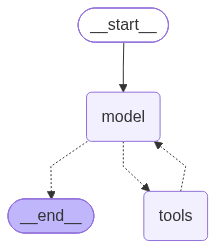

In [134]:
agent

In [135]:
que = "What is (2 + 3) * 7"
res = agent.invoke({ "messages": [ {"role":"user", "content":que} ] })

In [136]:
for msg in res["messages"]:
    msg.pretty_print()

================================ Human Message =================================

What is (2 + 3) * 7
================================== Ai Message ==================================
Tool Calls:
  add_numbers (fc_ec3f7ee2-9485-4875-a183-9be0b99b0035)
 Call ID: fc_ec3f7ee2-9485-4875-a183-9be0b99b0035
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: add_numbers

5
================================== Ai Message ==================================
Tool Calls:
  multiply_numbers (fc_e1c1d8d3-87cb-4ef1-8086-228c5f1f27ba)
 Call ID: fc_e1c1d8d3-87cb-4ef1-8086-228c5f1f27ba
  Args:
    a: 5
    b: 7
================================= Tool Message =================================
Name: multiply_numbers

35
================================== Ai Message ==================================

35


#### 7.3 Agent -  `memory`

In [137]:
from langgraph.checkpoint.memory import InMemorySaver

In [138]:
agent = create_agent(
    system_prompt="""
        You always call tools for user question. 
    """,
    model=llm,
    tools=[send_email, add_numbers, multiply_numbers],
    checkpointer=InMemorySaver()
)

In [139]:
while True:
    query = input("User: ")
    if query == "exit":
        break
    
    res = agent.invoke(
        { "messages": [ {"role":"user", "content":query} ] },
        {"configurable": {"thread_id": "user_1"}}
        )
    
    ans = res["messages"][-1].content
    print("AI: ", ans)

AI:  The sum of 7 and 9 is **16**.
[TOOL] Called sarthakjain4452@gmail.com
AI:  ✅ Email sent successfully to sarthakjain4452@gmail.com.


#### 8. `Prebuilt middleware`

###### `Summarization` middleware

In [140]:
from langchain.agents.middleware import SummarizationMiddleware

CHAT = [
    "My order id is ORD-4471.",
    "It was a Nikon Z50 camera.",
    "The box came open.",
    "The lens cap is missing.",
    "I want a replacement, not a refund.",
    'I love react js, and want to learn it',
    'Who is PM of India ?'
]

agent = create_agent(
    system_prompt="""
        You are a helpfull assistant, reply in one short line
    """,
    model=llm,
    tools=[],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=llm,
            trigger=("messages", 6),
            keep=("messages", 2)
        )
    ]
)


In [141]:
config = {"configurable": {"thread_id": "user_2"}}

for msg in CHAT:
    agent.invoke(
        { "messages": [ {"role":"user", "content":msg} ] },
        config=config
    )
    
    print("Messages in history: ", len(agent.get_state(config).values["messages"]))
    

Messages in history:  2
Messages in history:  4
Messages in history:  6
Messages in history:  4
Messages in history:  6
Messages in history:  4
Messages in history:  6


In [ ]:
# agent.get_state(config).values["messages"]

In [142]:
res = agent.invoke(
        { "messages": [ {"role":"user", "content":"What is my camera name"} ] },
        config=config
    )

In [143]:
print(res["messages"][-1].content)

Your camera is a Nikon Z50.


##### `PIIMiddleware` 

In [144]:
from langchain.agents.middleware import PIIMiddleware

agent = create_agent(
    model=llm,
    tools=[],
    middleware=[
        PIIMiddleware("email", strategy="redact", apply_to_input=True),
        PIIMiddleware("credit_card", strategy="redact", apply_to_input=True),
    ],
)

In [145]:
query = "Hello, I received email from sarthak@gmail.com for the payment of credit card 4111 1111 1111 1111"
res = agent.invoke({
    "messages": [ {"role":"user", "content":query} ]
})


In [146]:
res["messages"][0].content

'Hello, I received email from [REDACTED_EMAIL] for the payment of credit card [REDACTED_CREDIT_CARD]'